# **MMME4125 2026/2027 Coursework**

**Student Name:** Callum O'Neill

**Student ID:** 20576144

# **Project Description**

In this coursework, you will analise historical data and build your own machine learning pipeline demonstrating your knowledge on data exploration, data preparation and machine learning model development to solve a prediction or classification task  of an engineering domain problem.

**Dataset:** You will select a data set from a range of data sets provided in this module's Moodle page.

**Overall task:** Utilising your selected data set, you will build at least two models of your choice either for regression or classification (depending on the data set you selected) from the ones covered during lectures (e.g. NN, Decision Trees, Randon Forest, CNN to name a few examples). Employ appropriate methods from the pandas, matplotlib, keras and sklearn libraries to analyse and process the dataset and for building predictive models.

**Note:** You must use only pandas, numpy, matplotlib, keras and sklearn or any other specific library that was covered during class for example for data augmentation. Do not use other libraries or external packages. Use of such packages may receive zero credit for the affected parts. 

**Format:** Use this Jupyter Notebook as a template to write your report/answers to questions in Markdown cells, supported by your source code in Code cells.

The project (and this notebook) are structured in three main tasks:

**(Task 1)** -  Data set selection & data exploration : Once you select the data set you will carry out an initial Exploratory Data Analysis (EDA). Some data sets might be too large, containing multiple features or measurements of multiple variables. As you explore your data, you will make a decision of which sub set of your data you will use for your prediction/classification task. **You will then discuss this decision with your lab tutor (you will book a slot for this during lab hours) and get feedback**. As it will be indicated later in this notebook, you will add as markdown your analysis of the EDA results, the feedback provided by the tutor and how this has been taken into account to move to the next task. 

**(Task 2)** - Data preparation : with your chosen dataset (or subset), you will carry out the data preparation. This will include data visualisation (e.g. patterns, class imbalance, outliers), dealing with any missing values, outlier handling, scaling/normalisation, feature extraction, data reduction/augmentation, creating of training,validaton and test sets). 

**(Task 3)** - Model Development & Metrics Analysis : once your data set is ready, select two ML approaches from the ones covered during the lectures and discuss your selection with your lab tutor (**you will need to book a second lab slot for this and get feedback**). You will add in a Markdown cell your rationale for chosing such models, providing details of the feedback provided by the lab tutor and how it was used to move forward. Additional rationale for the specific hyper-parameters should also be included. Implementation should be added in a Code cell with appropriate code comments. Appropriate metrics for the model used should be implemented and presented (e.g. RMSE, Precision, Recall, F-Score, confusion matrix). You may want to try multiple hyper parameters to understand how the model behaves and if further iprovement can be obtained. In a Markdown cell, please explain the results obtained on both models and present a discussion of results. This discussion should include your insights on how model design/hyper-parameters affected the quality of the results.


Ensure your code produces the corresponding plots or results addressing the questions. Rename this .ipynb file to 202627_MMME4125_cw_XXX.ipynb, where XXX is your username (e.g., psxyz), and submit it to Moodle by **DATE**

**Marks**: The coursework is worth a total of 100 marks (accounting for 70% of the module grade). Marks will be awarded based on your understanding of machine learning theories, the informativeness and presentation of your code, visualisations, results (e.g., code comments, necessary labels in plots) and analysis, evidence of feedback and how it was addressed, your self-learning ability in solving the specific problem, and how succinct and clear your report writing is.

In [21]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from pathlib import Path

<div class="alert alert-success" style="text-align:left;">
<h2>Task 1. Dataset Selection & Exploratory Data Analysis<span style="float:right;">[25 marks]</span></h2></div>

### Task 1a. <span style="color:red">(10 marks)</span>

- *Start by introducing the engineering problem that you will be addressing, what the current industrial practice is to solve this problem and why ML is a good approach to solve it (3 marks).*
- *Explain the data set you have selected by providing details on what each variable represents, if you suspect there are any likely measurement problems, if there are any variables that could introduce leakage and if any mechanical principles may provide initial plausible relationships across these variables (5 marks).*
- *Finally explain why this is a regression or a classification task (2 marks).*

#### Engineering problem

The problem my case study is addressing is the identification of abnormal drilling conditions during robotic drilling. Conventional non-machine-learning approaches include post-process inspection and analysing torque thresholds. I believe applying machine learning is a good approach to solve the problem as traditional methods may fail to detect markers of anomalies characterised by relationships between multiple variables, especially when detection relies on predetermined variable thresholds. A machine learning approach can analyse multiple recorded signals and investigate the presence of hidden patterns/non-linear relationships which may identify abnormal conditions that could be missed by a traditional approach.

#### Dataset description

The paper establishes that the original study used two stacked aluminium plates, records signals at 1 kHz and reports 305 drilling cycles. Each experiment sees several drilling cycles completed on a workpiece. Each dataset subfolder organises experiments by different drilling conditions:

- **Normal**: Fully ideal conditions with holes of a good quality.
- **Low pressure**: Fully ideal conditions except the air pressure to the pressure-foot is halved.
- **Gap**: Normal conditions except the plates have 0.75 mm thick washers between them.
- **Short**: Normal conditions except the drill bit is set back in the collet by ~ 5 mm, meaning it doesn't break through the second plate.
- **Uneven tool**: Normal conditions except one face of the drill bit has been ground down to move the point slightly off centre.

The paper highlights another category:

- **Tolerance**: Fully ideal conditions with holes out of tolerance.

Tolerance is not given a separate subfolder in the dataset and is mixed in with the normal experiments, hence why I will be omitting it as a classification label. Instead I will choose to combine 'normal' and 'tolerance' into an 'nominal' label. This label refers to the experimental conditions, not the hole quality outcome.

For all of these conditions, a drilling cycle can be considered a failure if any of the following criteria are met:

- Incorrect hole diameter.
- Excessive burr height.
- Incomplete drilling.

Meaning for this dataset, the following is true:

- A failure can still have acceptable outcomes in up to 2/3 of the criteria, but not all 3.
- Almost all conditions can theoretically produce holes of an acceptable quality (the exceptions being 'tolerance' and 'short' as they are by definition poor quality).

Each experiment subfolder provides `.csv` files with the following variables being recorded from each drilling cycle:

| **Variables in `.csv` headers** | **Meaning** |
| :-- | :-- |
| Index | Sample number |
| Time | Time (ms) |
| INORM | Spindle motor peak current amplitude (A) |
| IEFF | Effective servo motor peak current amplitude (A) |
| TCMD | Torque requested by controller (%) |
| POSF | Z-axis position (mm) |

##### Justification of project scope

Each subfolder contains `nB.txt` files for each hole drilled, where n is the hole number (i.e. hole 1 = `1B.txt` and hole 2 = `2B.txt` etc). The dataset has file names with uppercase and lowercase 'B', with no information to state why. These files contain data relating to surface-height measurements used to calculate the burr height, but do not explicitly say which `.csv` relates to which file. Each subfolder also contains a single `GEOMETRY.txt` file which contains data about the measured diameter and circularity of each hole. Again, the file does not explicitly say which `.csv` relates to which hole. The dataset and research paper also fail to provide the tolerances used to determine whether a burr height or hole diameter is acceptable, restricting my ability to extend the case study into assessing if a given hole will pass/fail under varying conditions. For these reasons I have chosen the scope of the case study to be a  drilling-condition classification as I cannot reliably determine/construct pass/fail labels. 

##### Measurement problems

I have identified the following to be potential measurement problems:

- Electrical noise.
- Missing samples.
- Inconsistent data.

I cannot accurately say if any of these are present until the data inspection phase of the analysis.

##### Sources of leakage

I have identified the following to be potential sources of data leakage:

- **Folder names**: Folder path names include the condition which could lead to shortcut learning. The case study will ensure not to feed the model the path names.
- **Recording date/Batch ID**: Because experiments for different conditions were recorded in different sessions, the model may see these as predictive features rather than the data. 
- **Related recordings**: Recordings from the same experiment (i.e. hole 1 and 2 on a given experiment) could share characteristics due to the physical setup, which could be picked up instead of the data.

I cannot accurately say if any of these are present until the data inspection phase of the analysis.

##### Mechanical relationships

I have identified the following to be potential mechanical relationships that could give pointers to initial relationships/characteristics:

- **Resistance in drilling changing motor current**: On contact with the plate, the z-axis servo motor will likely need to produce more torque to feed the tool into the workpiece, increasing the current.
- **Controller torque command changing motor current**: The controller's torque command could affect the current due to requests from the motor's controller, but equally both could respond to the same change in mechanical load.

#### Regression vs classification


This model is a classification problem as rather than determining a continuous numerical output (for example, predicted hole diameter), it attempts to identify a discrete anomaly classification label.

### Task 1b. <span style="color:red">(5 marks)</span>

- *Select a subset of the data to be visualised. Include a rationale for inspecting this particular subset of data (2 mark).*
- *Produce at least 3 plots (1 mark each) to visualise patterns, distribution, class imbalance, outliers and correlations. The types of plots you use will  be determined by the type of data you are handling. These plots should be informative of the next steps you will carry out during data preparation.*

#### Subset selection

The subset of data I will be working on based on subfolder:

| **Data** | **Status** | **Justification** |
| :-- | :-- | :-- |
| 2025.05.09 Set-up for experiment (AS4 & Anomaly) | omitted | setup data |
| 2025.05.14 AA2 As4 & Anomaly | omitted | undefined condition |
| 2025.05.14 AA3 | kept | useful data for 'nominal' label |
| 2025.05.14 AA4 | kept | useful data for 'nominal' label |
| 2025.05.15 AA5 | kept | useful data for 'nominal' label |
| 2025.06.02 AA A1 Low pressure | kept | useful data for 'low pressure' label |
| 2025.06.03 AA A2 Low pressure | kept | useful data for 'low pressure' label |
| 2025.06.03 AA A3 Low pressure | kept | useful data for 'low pressure' label |
| 2025.06.04 AA A4A Gap | kept | useful data for 'gap' label |
| 2025.06.04 AA A4B Gap | kept | useful data for 'gap' label |
| 2025.06.09 AA A5 Gap | kept | useful data for 'gap' label |
| 2025.06.10 AA A6 Gap | kept | useful data for 'gap' label |
| 2025.06.11 AA A7 Short | kept | useful data for 'short' label |
| 2025.06.23 AA A8 Short | kept | useful data for 'short' label |
| 2025.06.24 AA A9 Short | kept | useful data for 'short' label |
| 2025.06.25 AA A10 Short | kept | useful data for 'short' label |
| 2025.07.02 AA A11 Uneven tool | kept | useful data for 'uneven' label |
| 2025.07.02 AA A12 Uneven tool | kept | useful data for 'uneven' label |
| 2025.07.03 AA A13 Uneven tool | kept | useful data for 'uneven' label |
| 2025.07.07 AA6 | omitted | undefined condition |
| 2025.07.10 AA7 | omitted | undefined condition |

For each subfolder, further narrowing can be done:

| **Data** | **Status** | **Justification** |
| :-- | :-- | :-- |
| `.csv` files | kept | contain relevant current data |
| `nB.txt` files | omitted | contains out-of-scope surface-height data |
| `GEOMETRY.txt` files | omitted | contains out-of-scope diameter/circularity data |

The `.csv` files can be further reduced:

| **Data** | **Status** | **Justification** |
| :-- | :-- | :-- |
| `... - Copy.csv` files | omitted | direct copies or same data with negligible rounding differences |
| `... _incomplete.csv` files | omitted | all values are zero |

#### Sorting conditions

In [22]:
conditions = {
    "Nominal": ["AA3", "AA4", "AA5"],
    "Low pressure": ["A1_low", "A2_low", "A3_low"],
    "Gap": ["A4A_gap", "A4B_gap", "A5_gap", "A6_gap"],
    "Short": ["A7_short", "A8_short", "A9_short", "A10_short"],
    "Uneven tool": ["A11_uneven", "A12_uneven", "A13_uneven"],
}

#### Function for getting file paths

In [23]:
def get_condition(file):
    path = {part.lower() for part in file.parts}

    for condition, folders in conditions.items():
        if path.intersection(folder.lower() for folder in folders):
            return condition

    return None

#### Loading recordings and calculate imbalance ratio

In [37]:
csv_files = sorted(Path("subset").rglob("*.csv"))

condition_counts = {}

for file in csv_files:
    condition = get_condition(file)
    if condition is not None:
        condition_counts[condition] = condition_counts.get(condition, 0) + 1

print("Number of files in each condition:")
for condition, count in condition_counts.items():
    print(f"  {condition}: {count}")

Number of files in each condition:
  Short: 55
  Uneven tool: 48
  Low pressure: 48
  Gap: 48
  Nominal: 47


The equation for the imbalance ratio (IR) is:

$$
IR = \frac{ N_{max} }{ N_{min} } \tag{1}
$$

Substituting $ N_{max} = 55 $ and $ N_{min} = 47$ into $(1)$:

$$ 
IR = \frac{55}{47} \approx  1.17
$$

The value of IR is low enough that it is considered a balanced dataset. 

#### Plots

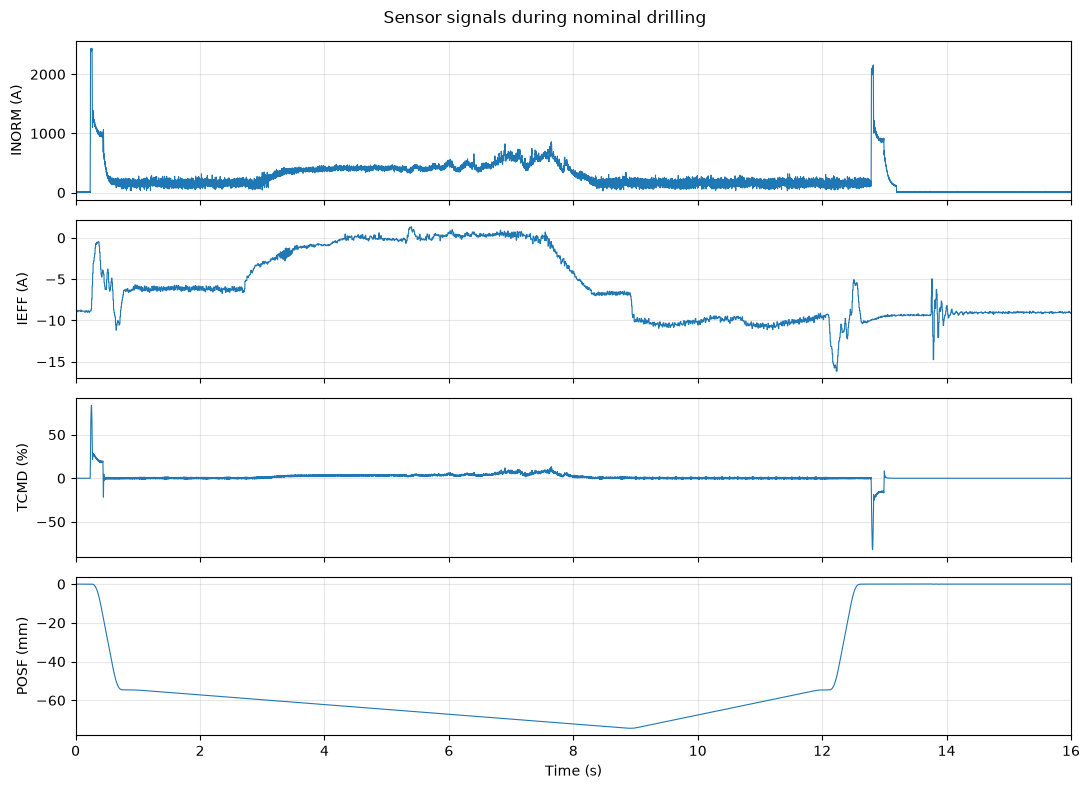

In [39]:

# Select a recording from the AA4 nominal experiment
file = next(
    f for f in csv_files
    if f.parent.name == conditions["Nominal"][1]
)

df = pd.read_csv(file, skiprows=[0, 1, 3])

signals = ["INORM", "IEFF", "TCMD", "POSF"]
units = ["A", "A", "%", "mm"]

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)

for ax, signal, unit in zip(axes, signals, units):
    ax.plot(df["Time"] / 1000, df[signal], linewidth=0.8)

    ax.set_ylabel(f"{signal} ({unit})")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 16)

fig.suptitle("Sensor signals during nominal drilling")
plt.tight_layout()
plt.show()


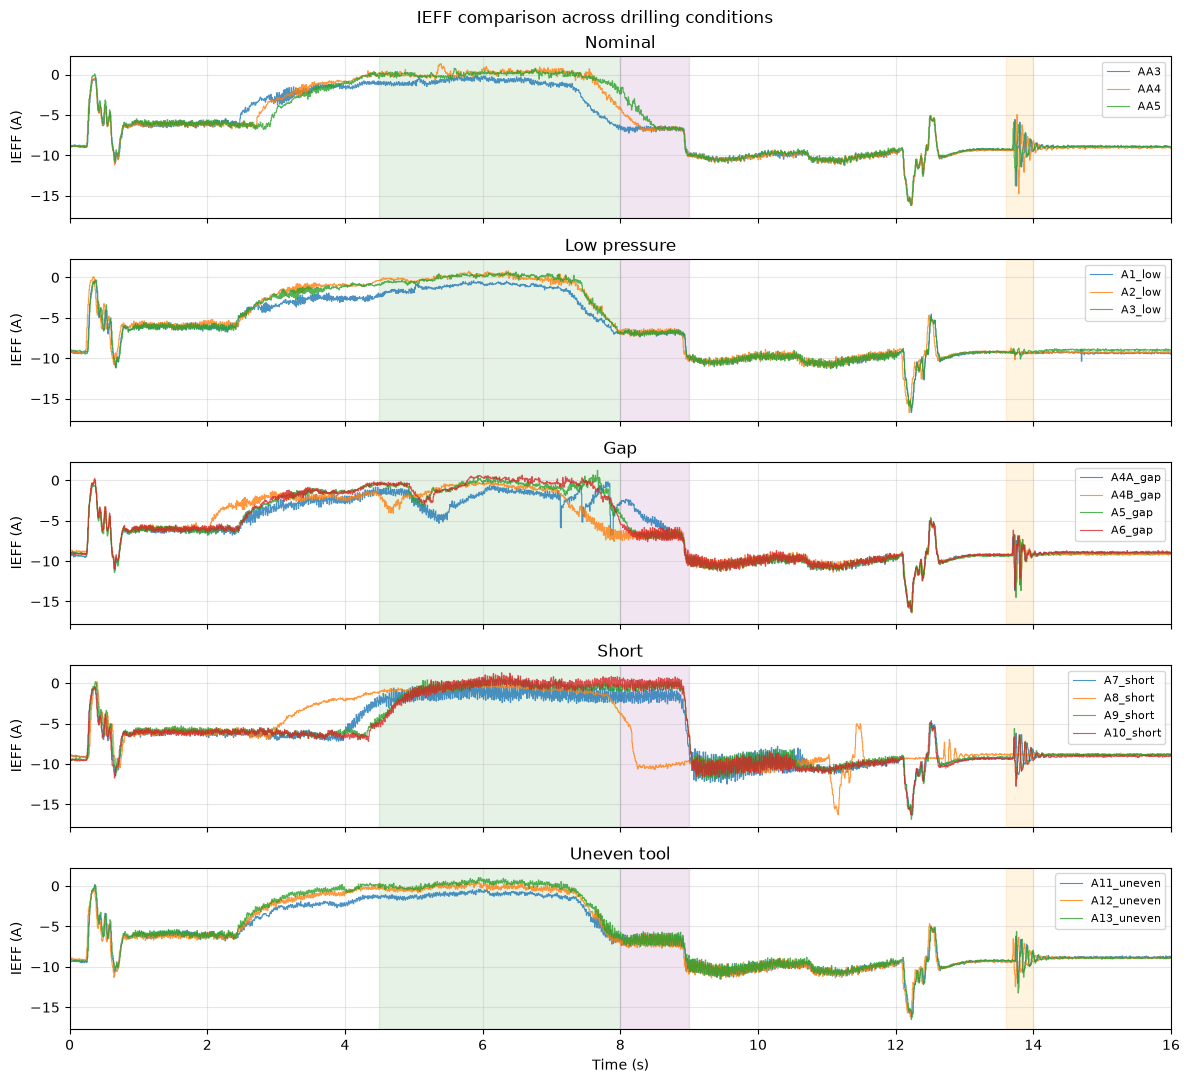

In [65]:
fig, axes = plt.subplots(5, 1, figsize=(12, 11),
                         sharex=True, sharey=True)

for ax, (condition, folders) in zip(axes, conditions.items()):

    for folder in folders:
        file = next(f for f in csv_files if f.parent.name == folder)
        df = pd.read_csv(file, skiprows=[0, 1, 3])

        ax.plot(
            df["Time"] / 1000,
            df["IEFF"],
            label=folder,
            linewidth=0.8,
            alpha=0.8
        )

    ax.axvspan(4.5, 8, color="green", alpha=0.10)
    ax.axvspan(8, 9, color="purple", alpha=0.10)
    ax.axvspan(13.6, 14, color="orange", alpha=0.12)

    ax.set_ylabel("IEFF (A)")
    ax.set_title(condition)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 16)

fig.suptitle("IEFF comparison across drilling conditions")
plt.tight_layout()
plt.show()

In [69]:
feature_rows = []

for file in csv_files:
    condition = get_condition(file)

    if condition is None:
        continue

    df = pd.read_csv(file, skiprows=[0, 1, 3])

    window_4p5_8 = df[df["Time"].between(4500, 8000)]
    window_8_9 = df[df["Time"].between(8000, 9000)]
    window_13p6_14 = df[df["Time"].between(13600, 14000)]

    feature_rows.append({
        "condition": condition,
        "IEFF_std_4.5_8": window_4p5_8["IEFF"].std(),
        "IEFF_std_8_9": window_8_9["IEFF"].std(),
        "IEFF_std_13.6_14": window_13p6_14["IEFF"].std()
    })

features = pd.DataFrame(feature_rows)

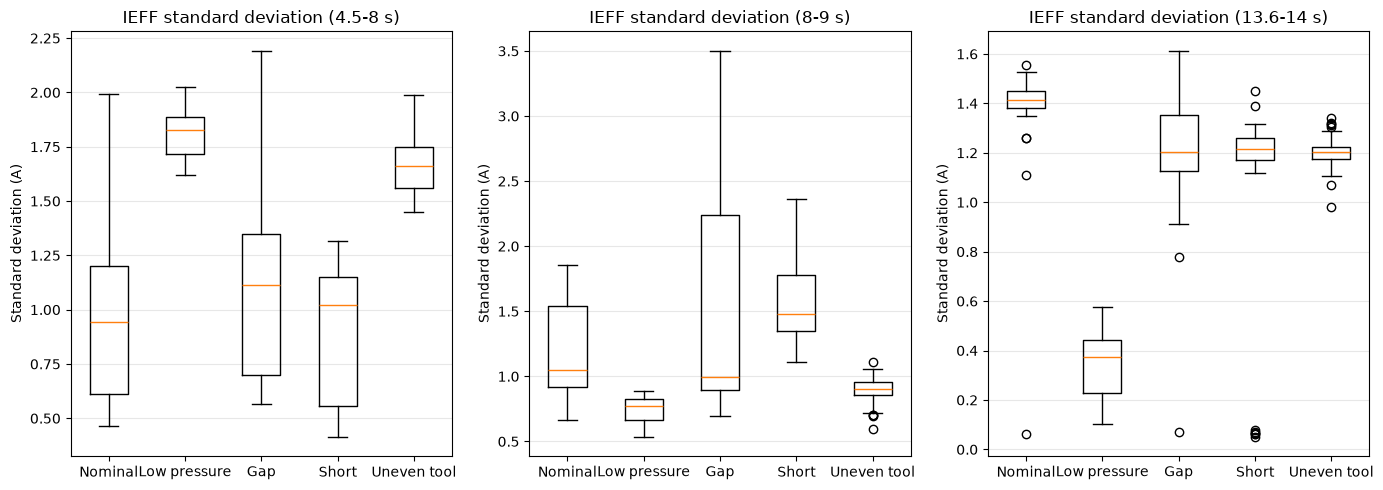

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

windows = {
    "4.5-8 s": "IEFF_std_4.5_8",
    "8-9 s": "IEFF_std_8_9",
    "13.6-14 s": "IEFF_std_13.6_14"
}

for ax, (label, column) in zip(axes, windows.items()):

    data = [
        features.loc[
            features["condition"] == condition, column
        ].dropna()
        for condition in conditions
    ]

    ax.boxplot(data)
    ax.set_xticks(range(1, len(conditions) + 1))
    ax.set_xticklabels(conditions.keys())

    ax.set_title(f"IEFF standard deviation ({label})")
    ax.set_ylabel("Standard deviation (A)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


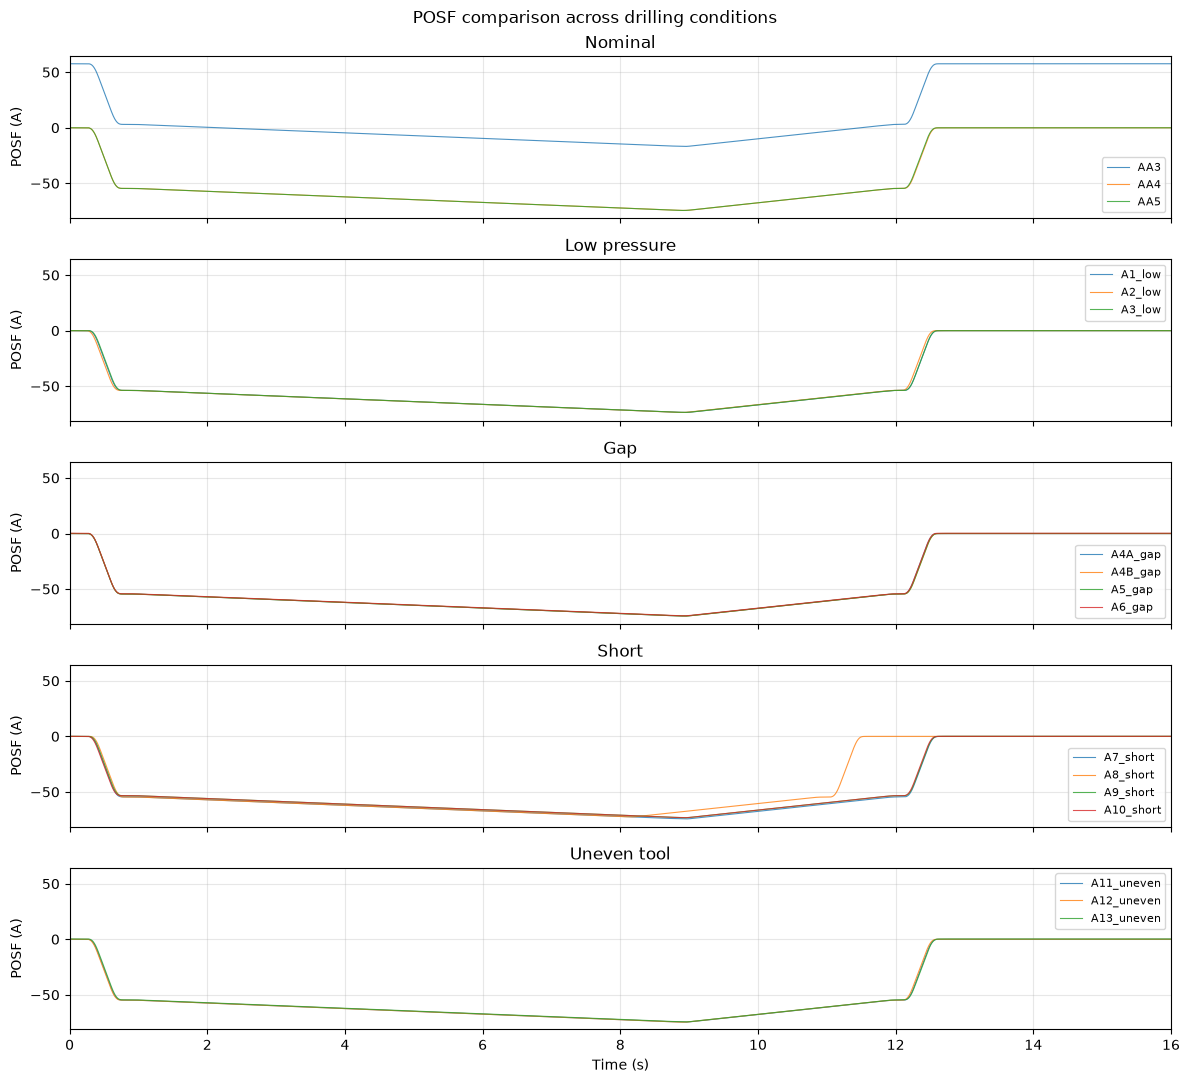

In [62]:
fig, axes = plt.subplots(5, 1, figsize=(12, 11),
                         sharex=True, sharey=True)

for ax, (condition, folders) in zip(axes, conditions.items()):

    for folder in folders:
        file = next(f for f in csv_files if f.parent.name == folder)
        df = pd.read_csv(file, skiprows=[0, 1, 3])

        ax.plot(
            df["Time"] / 1000,
            df["POSF"],
            label=folder,
            linewidth=0.8,
            alpha=0.8
        )

    ax.set_ylabel("POSF (A)")
    ax.set_title(condition)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, 16)

fig.suptitle("POSF comparison across drilling conditions")
plt.tight_layout()
plt.show()

### Task 1c. <span style="color:red">(10 marks)</span>

- *By using your plots from 1b, provide an analysis of the data (e.g. observed patterns, correlations, potential best predictors) and briefly explain how each code snippet supports your evaluation of potential issues with the data (5 marks).*
- *Once you have done your analysis/insights you should discuss this with your lab tutor (you need to book a slot in lab hours for this), capture that feedback, report it here as well as a reflection of how the feedback informs the next steps of data processing (5 marks).*

#### Plot 1 — Individual drilling cycle

- **Observation:** The four recorded variables represent different aspects of the drilling cycle. Their behaviour changes throughout the recording as the machine moves through different operating stages.
- **Significance:** The time-dependent behaviour suggests that analysing specific stages of the cycle may be more useful than treating the entire recording equally. In particular, the drilling stage (approximately 4.5–8 s) and the later retraction/release stage (approximately 13.6–14 s) are worth investigating separately.
- **Limitation:** A single nominal recording cannot establish how consistent these patterns are across repeated cycles or different experimental conditions. Fixed time windows may also fail to align with the same physical event in every recording.



#### Plot 2 -


### Tutor Feedback and Reflection

#### Initial Feedback from Giovanna 23/10/26

- I can decide whether I want to look at raw data vs features
- Decide if I can cut sections out of signal or reduce resolution by viewing the data
- I can run an ablation study to find out how much data is needed and see if I can lower sampling rate
- look at how many samples to see if they all have the same


<div class="alert alert-success" style="text-align:left;">
<h2>Task 2. Data Preparation<span style="float:right;">[40 marks]</span></h2></div>

*### <span style="color:red">IMPORTANT NOTE: </span> 
This the beginning of your ML building pipeline. All transformations that happen to the data from here onwards may be stateless or stateful. Make a concious decision at which step of the entire process you need to split your data set into training, validation and test set. **Add an additional Code cell** for data splitting when you think it is reasonable to do so as well as **add a Markdown cell** to explain why the data set is splitted at this point of the ML pipeline and the impact data transformation operations might have on the validity of the model if the splitting is not carried out beforehand. You should also justify your train-validation-test splitting stategy.*
### <span style="color:red">(8 marks) </span>

### Task 2a. Data Cleaning <span style="color:red">(7 marks)</span>

*Using the libraries specificied at the top of the notebook or any other one covered in class, start cleaning your data by handling missing values, handling any duplicates and deal with outliers. Justify your methods.*

*Task 2a. Add your justification here*

In [8]:
# Task 2a. Add your code here

### Task 2b. Data Transformation <span style="color:red">(5 marks)</span>

*Perform any necessary normalisation and encoding of categorical variables. Please explain why this step is necessary when building a predictive model and justify the method used.*

In [9]:
# Task 2b. Add your code here

*Task 2b. Add your explanation here*

### Task 2c. Data Reduction/Augmentation  <span style="color:red">(10 marks)</span>

*Based on your data set implement either data reduction or data augmentation depending on the needs of the problem and data (5 marks). Explain why data reduction or data augmentation is necessary in the context of your engineering problem and the data set you selected as well as justify the methods used (5 marks). One thing to note is that depending on your data set, data reduction might have to be done after Task 2d Feature Engineering, so make sure you apply these two steps (Task 2c and Task 2d) in the correct order according to your data.* 

***Note:*** *If you do have to do 2d before 2c, then just make sure your code is in the correct order in the code cells below.*

In [10]:
# Task 2c. Add your code here

*Task 2c. Add your explanation and justification here*

### Task 2d. Feature Engineering   <span style="color:red">(10 marks)</span>

- *An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier.*
- *Perform any feature engineering that you might think it is ideal for the type of task you are aiming (4 marks). This could include statistical features, rolling window statistics,  frequency analysis (FFT) or any others covered in lectures.*
- *If either you are going to work directly with the raw data, or you will be engineering features, justify why this is the case in the context of the engineering problem you are trying to solve, justifying any specific features used (3 marks).* 
- *In the case of raw data, perform any additional transformation that would be needed to work with this raw data directly.*
- *Assess whether all data is ready for model building. If not, complete the preparation of a model-ready dataframe from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared dataframe are directly suitable for the machine learning task, state why this is the case  and state what(if anything) still needs processing, and process / make the necessary adjustment in the data accordingly (3 marks).*

In [11]:
# Task 2c. Add your code here

Task 2c. Add your explanations/justifications here

<div class="alert alert-success" style="text-align:left;">
<h2>Task 3. ML Model Building<span style="float:right;">[35 marks]</span></h2></div>

### Task 3a. Building a base  model <span style="color:red">(10 marks)</span>

*Now, after meeting your tutor for the second time to discuss your preliminary model selection and reasons for such method (you need to book again a slot during your lab for this) select and build a baseline model from scratch (e.g. define architecture in the case of NN) to predict or classify according to your problem using the preprocessed dataset. *

- *Train the model and report **three different** evaluation metrics (3 marks).*
- *Reflecting from  your tutor feedback, explain how this feedback influenced the ML model selected, why is it appropriate for the task? why the hyper-parameters used? (4 marks)*
- *For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible predictions/classifications, i.e. what the values within the metric mean (3 marks).*

In [12]:
#Add your code here

Add your justification for metrics here and what the results obtained mean.

### Task 3b. Hyper-parameter exploration <span style="color:red">(10 marks)</span>

- *You have now build a base model, with some initial results. It is now your task to experiment with hyper-parameters (5 marks) to see if you can improve the quality of your results.*
- *It is up to you how you approach this process, but you need to justify (5 marks ) the approach you are taking and discuss the results. What effect is having the changes you are doing to the approach?*

In [13]:
#perform your different hyper-parameter optimisation/changes here

Add here your justification for how you are approaching the hyper-parameter tuning  and discuss your results.

### Task 3c. Additional Models and Final Analysis <span style="color:red">(15 marks)</span>

*Implement at least one more method of your choice.Report model quality with clear evidence (metrics). Compare with the baseline using supportive tables or visualisations (4 marks), and discuss the strengths and limitations of each (3 marks).* 

*Finally, provide a discussion (8 marks) on:*

- *Why this type of model and would you deploy it in a real environment? why?*
- *Under what operating conditions would you not trust it? how could you improve it?*
- *What additional sensor would you collect and why?*
- *Are the important features physically plausible?*

In [14]:
# your implementaiton of additional methods here together with metrics

Add here your discussion on strengths and limitations of each method